# 上游 有 在使用Send 一个句子 一个任务   ====  下游 就需要一个MapReduce

动态扇入（Dynamic Fan-in）：多个并行任务执行完成后，将它们的结果动态汇合到一个下游节点进行统一处理。

它通常与**动态扇出Dynamic Fan-out**配合使用。


动态扇出：
for input_value in input_values:    tasks.append(        Send("mapper_node", {"input_value": input_value})    )
如果有 3 句话，就创建 3 个 Mapper 任务；如果有 100 句话，就创建 100 个任务。

如果有 3 句话，就创建 3 个 Mapper 任务；如果有 100 句话，就创建 100 个任务。

动态扇入：
class OverAllState(TypedDict):    entries: Annotated[list[tuple[str, int]], add]

三个 Mapper 分别返回：

Mapper 1{"entries": [("hello", 1), ("world", 1)]}

Mapper 2{"entries": [("hello", 1), ("atguigu", 1)]}

Mapper 3{"entries": [("hello", 1), ("llm", 1)]}


LangGraph 通过 add Reducer 合并：
entries = [    ("hello", 1),    ("world", 1),    ("hello", 1),    ("atguigu", 1),    ("hello", 1),    ("llm", 1)]

接着 reducer_node 统一计算：
word_counts = {    "hello": 3,    "world": 1,    "atguigu": 1,    "llm": 1}


# Fan-out:1→N Fan-in:N→1


2026-11-11 17:45:26.309 | INFO     | __main__:reducer_node:61 - reducer shuffle entries:{'hello': [1, 1, 1], 'world': [1], 'atguigu': [1], 'llm': [1]}
2026-11-11 17:45:26.310 | INFO     | __main__:reducer_node:67 - reducer {'hello': 3, 'world': 1, 'atguigu': 1, 'llm': 1}


{'input_values': ['hello world', 'hello atguigu', 'hello llm'], 'entries': [('hello', 1), ('world', 1), ('hello', 1), ('atguigu', 1), ('hello', 1), ('llm', 1)], 'word_counts': {'hello': 3, 'world': 1, 'atguigu': 1, 'llm': 1}}


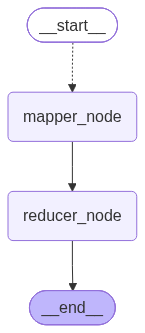

In [1]:
from typing import TypedDict, Annotated, Sequence

from langgraph.constants import START, END
from langgraph.graph import StateGraph
from langgraph.types import Send
from operator import add
from loguru import logger


#1. 声明状态
#1.1 声明全局状态
class OverAllState(TypedDict):
    input_values: list[str]
    entries: Annotated[list[tuple[str, int]], add]
    word_counts: dict[str, int]


class MaperInputState(TypedDict):
    input_value: str


#2. 声明节点
#2.1 分发节点
def router_node(state: OverAllState) -> Sequence[Send]:
    input_values = state["input_values"]
    task = []
    for input_value in input_values:
        task.append(
            Send(
                "mapper_node",
                {"input_value": input_value}
            )
        )
    return task


#2.2 接收单独的一句话, 切分为单词  组装为元组放到全局状态中
def mapper_node(state: MaperInputState) -> OverAllState:
    input_value = state["input_value"]
    words = input_value.split(" ")
    #  (hello, 1), (world, 1)
    entries = []
    for word in words:
        entries.append((word, 1))
    return {
        "entries": entries
    }


#2.3 聚合所有的mapper_node拆分的元组进行合并
def reducer_node(state: OverAllState) -> OverAllState:
    entries = state["entries"]
    shuffle_dict = {}
    # hello   -> [1, 1, 1]
    for k, v in entries:
        if k not in shuffle_dict:
            shuffle_dict[k] = [v]
        else:
            shuffle_dict[k].append(v)

    logger.info("reducer shuffle entries:{}", shuffle_dict)
    reduce_dict = {}

    for k, v in shuffle_dict.items():
        reduce_dict[k] = sum(v)

    logger.info("reducer {}", reduce_dict)

    return {
        "word_counts": reduce_dict
    }


#3. 构件图
builder = StateGraph(state_schema=OverAllState)
builder.add_node("mapper_node", mapper_node)
builder.add_node("reducer_node", reducer_node)
builder.add_conditional_edges(START, router_node, path_map=["mapper_node"])
builder.add_edge("mapper_node", "reducer_node")
builder.add_edge("reducer_node", END)
graph = builder.compile()

res = graph.invoke({
    "input_values": ["hello world", "hello atguigu", "hello llm"]
})
print(res)

from IPython.display import display

display(graph)



#下面是修改后的完整代码。将 router_node 注册为真正的 Node，同时保留原来的 MapReduce 逻辑。

2026-11-11 17:54:12.708 | INFO     | __main__:router_node:27 - router_node: ['hello world', 'hello atguigu', 'hello llm']
2026-11-11 17:54:12.710 | INFO     | __main__:mapper_node:56 - mapper_node: [('hello', 1), ('world', 1)]
2026-11-11 17:54:12.713 | INFO     | __main__:mapper_node:56 - mapper_node: [('hello', 1), ('llm', 1)]
2026-11-11 17:54:12.713 | INFO     | __main__:mapper_node:56 - mapper_node: [('hello', 1), ('atguigu', 1)]
2026-11-11 17:54:12.718 | INFO     | __main__:reducer_node:76 - reducer shuffle entries: {'hello': [1, 1, 1], 'world': [1], 'atguigu': [1], 'llm': [1]}
2026-11-11 17:54:12.719 | INFO     | __main__:reducer_node:84 - reducer result: {'hello': 3, 'world': 1, 'atguigu': 1, 'llm': 1}


{'input_values': ['hello world', 'hello atguigu', 'hello llm'], 'entries': [('hello', 1), ('world', 1), ('hello', 1), ('atguigu', 1), ('hello', 1), ('llm', 1)], 'word_counts': {'hello': 3, 'world': 1, 'atguigu': 1, 'llm': 1}}


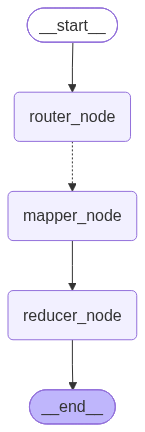

In [2]:

from typing import TypedDict, Annotated, Sequence
from langgraph.constants import START, END
from langgraph.graph import StateGraph
from langgraph.types import Send
from operator import add
from loguru import logger


# 1. 声明状态

# 1.1 全局状态
class OverAllState(TypedDict):
    input_values: list[str]
    entries: Annotated[list[tuple[str, int]], add]
    word_counts: dict[str, int]


# 1.2 Mapper 私有状态
class MapperInputState(TypedDict):
    input_value: str


# 2. 声明节点

# 2.1 Router Node：真正的图节点
def router_node(state: OverAllState) -> dict:
    logger.info("router_node: {}", state["input_values"])
    return {}


# 2.2 Dispatch：生成动态 Send 任务
def dispatch(state: OverAllState) -> Sequence[Send]:
    tasks = []

    for input_value in state["input_values"]:
        tasks.append(
            Send(
                "mapper_node",
                {"input_value": input_value}
            )
        )

    return tasks


# 2.3 Mapper：将句子切分为单词
def mapper_node(state: MapperInputState) -> dict:
    input_value = state["input_value"]
    words = input_value.split()

    entries = []

    for word in words:
        entries.append((word, 1))

    logger.info("mapper_node: {}", entries)

    return {
        "entries": entries
    }


# 2.4 Reducer Node：统计单词
def reducer_node(state: OverAllState) -> dict:
    entries = state["entries"]

    # Shuffle：根据单词分组
    shuffle_dict = {}

    for k, v in entries:
        if k not in shuffle_dict:
            shuffle_dict[k] = [v]
        else:
            shuffle_dict[k].append(v)

    logger.info("reducer shuffle entries: {}", shuffle_dict)

    # Reduce：计算出现次数
    reduce_dict = {}

    for k, v in shuffle_dict.items():
        reduce_dict[k] = sum(v)

    logger.info("reducer result: {}", reduce_dict)

    return {
        "word_counts": reduce_dict
    }


# 3. 构建 Graph
builder = StateGraph(state_schema=OverAllState)

# 3.1 注册节点
builder.add_node("router_node", router_node)
builder.add_node("mapper_node", mapper_node)
builder.add_node("reducer_node", reducer_node)

# 3.2 定义边
builder.add_edge(START, "router_node")

# Router Node -> 动态分发 Mapper
builder.add_conditional_edges(
    "router_node",
    dispatch,
    path_map=["mapper_node"]
)

# Mapper -> Reducer
builder.add_edge("mapper_node", "reducer_node")
builder.add_edge("reducer_node", END)


# 4. 编译 Graph
graph = builder.compile()


# 5. 执行
res = graph.invoke({
    "input_values": [
        "hello world",
        "hello atguigu",
        "hello llm"
    ]
})

print(res)


# 6. 可视化
from IPython.display import display, Image

display(Image(graph.get_graph().draw_mermaid_png()))
